# 02. EDA, часть 2: тип станции, погода, плата за въезд, события

Что делаем:
1. **Индекс типа станции**: одно число вместо номера кластера (решение по итогам ноутбука 01).
2. **Погода**: как дождь, снег и температура меняют спрос — по часам и по типам станций; буран февраля 2026.
3. **Город или сетка**: нужна ли погода по районам.
4. **Плата за въезд (05.01.2025)**: «разность разностей» — станции в зоне против остальных.
5. **События**: поиск всплесков на всех 424 станциях, чтобы решить, нужен ли признак событий.

**Как меряем эффект погоды.** Для каждой станции и часа считаем «обычное» значение — медиану того же
часа и дня недели в этом же месяце. Эффект = фактические входы / обычные. Так сезон и тип дня
не смешиваются с погодой. Закрытые станции и праздники исключены.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from dataset import load_dataset

COL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.figsize": (11, 4), "figure.dpi": 110,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.max_rows", 100, "display.max_colwidth", 70)

DOW = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
CL_NAMES = {0: "окраины", 1: "спальные", 2: "смешанные", 3: "деловые"}
TRAIN_END = pd.Timestamp("2026-03-31 23:00")   # всё, что «учит» признаки, — только из обучающего периода

def pct(v):
    return f"{v:+.1%}"

In [2]:
cols = ["station_complex_id", "transit_timestamp", "ridership", "is_closed", "hour", "dow",
        "is_holiday", "holiday_name", "in_cbd"]
df = load_dataset(weather=None)[cols]
df["station_complex_id"] = df["station_complex_id"].astype(str).astype("category")
df["date"] = df["transit_timestamp"].dt.normalize()
df["ym"] = (df["transit_timestamp"].dt.year * 100 + df["transit_timestamp"].dt.month).astype("int32")

st = pd.read_parquet("../data/processed/stations.parquet")
name = st.set_index("station_complex_id")["station_complex"]
clusters = pd.read_csv("../data/processed/station_clusters.csv", dtype={"station_complex_id": str})
cl_map = clusters.set_index("station_complex_id")["cluster"]

print(f"{len(df):,} строк; память {df.memory_usage(deep=True).sum() / 1e9:.2f} ГБ")

13,868,192 строк; память 0.44 ГБ


## 1. Индекс типа станции

`commute_index` = доля входов буднего дня в 6–10 ч минус доля в 16–20 ч.
Около +0,3 — спальная станция (уезжают утром), около −0,3 — деловая (уезжают вечером), около 0 — смешанная.
Считается **только по обучающему периоду** (до апреля 2026), чтобы в признак не попала информация из теста.

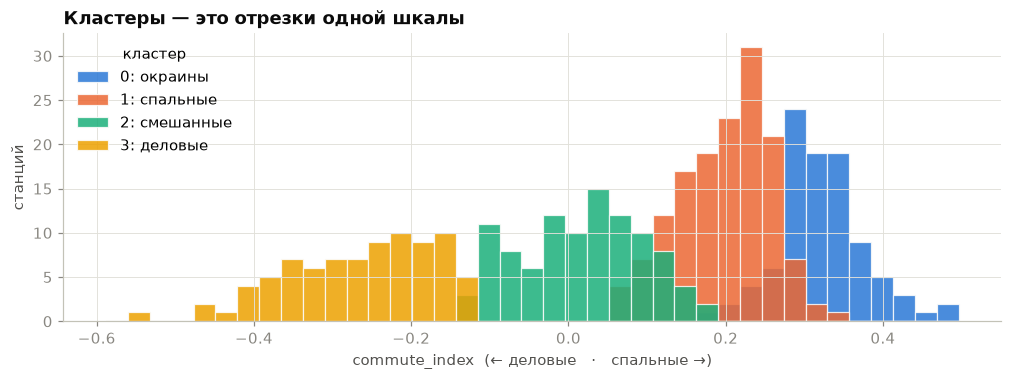

Самые «деловые»: 5 Av/53 St (E,F); 47-50 Sts-Rockefeller Ctr (B,D,F,M); 42 St-Bryant Pk/5 Av (7,B,D,F,M); 5 Av/59 St (N,R,W); Broad St (J,Z)
Самые «спальные»: Buhre Av (6); 104 St (A); Morris Park (5); 88 St (A); 111 St (A)
Сохранено: data/processed/station_features.csv


In [3]:
wk = df[(df["transit_timestamp"] <= TRAIN_END) & (df["is_closed"] == 0) &
        (df["dow"] < 5) & (df["is_holiday"] == 0)]
prof = wk.groupby(["station_complex_id", "hour"], observed=True)["ridership"].mean().unstack().fillna(0)
shares = prof.div(prof.sum(axis=1), axis=0)
commute = (shares.loc[:, 6:9].sum(axis=1) - shares.loc[:, 16:19].sum(axis=1)).rename("commute_index")
commute.index = commute.index.astype(str)
del wk

feat = commute.round(4).reset_index()
feat["cluster"] = feat["station_complex_id"].map(cl_map)
feat.to_csv("../data/processed/station_features.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 3.4))
bins = np.linspace(commute.min(), commute.max(), 40)
for c in sorted(feat["cluster"].dropna().unique()):
    ax.hist(feat.loc[feat["cluster"] == c, "commute_index"], bins=bins, color=COL[int(c)],
            alpha=0.85, label=f"{int(c)}: {CL_NAMES.get(int(c), '')}", edgecolor="#fcfcfb", linewidth=0.8)
ax.set_xlabel("commute_index  (← деловые   ·   спальные →)"); ax.set_ylabel("станций")
ax.set_title("Кластеры — это отрезки одной шкалы"); ax.legend(title="кластер")
plt.show()

ex = feat.assign(name=feat["station_complex_id"].map(name)).sort_values("commute_index")
print("Самые «деловые»:", "; ".join(ex.head(5)["name"]))
print("Самые «спальные»:", "; ".join(ex.tail(5)["name"]))
print("Сохранено: data/processed/station_features.csv")

## 2. Погода и спрос

Сначала считаем «обычное» значение для каждой станции и часа (медиана того же часа и дня недели
в том же месяце), затем суммируем по типам станций. Ячейка может выполняться 1–2 минуты.

In [4]:
base = df[(df["is_closed"] == 0) & (df["is_holiday"] == 0)].copy()
base["typical"] = (base.groupby(["station_complex_id", "ym", "dow", "hour"], observed=True)["ridership"]
                       .transform("median").astype("float32"))
base["cluster"] = base["station_complex_id"].astype(str).map(cl_map).astype("int8")

by_cl = (base.groupby(["cluster", "transit_timestamp"], observed=True)[["ridership", "typical"]].sum()
             .reset_index())
by_sys = by_cl.groupby("transit_timestamp")[["ridership", "typical"]].sum().reset_index()

w = pd.read_parquet("../data/raw/weather_hourly.parquet")
WCOLS = ["temperature_2m", "precipitation", "rain", "snowfall", "snow_depth", "wind_speed_10m"]

def add_weather(t):
    t = t.merge(w[["transit_timestamp"] + WCOLS], on="transit_timestamp", how="left")
    t["ratio"] = t["ridership"] / t["typical"]
    t["hour"] = t["transit_timestamp"].dt.hour
    t["dow"] = t["transit_timestamp"].dt.dayofweek
    peak = t["hour"].isin([7, 8, 9, 16, 17, 18, 19])
    t["period"] = np.select([(t["dow"] < 5) & peak, t["dow"] < 5], ["будни, пик", "будни, вне пика"], "выходные")
    return t[(t["typical"] > 0) & t["hour"].between(6, 23)]   # ночью входов мало, отношения шумные

by_cl, by_sys = add_weather(by_cl), add_weather(by_sys)
print(f"Часов в анализе: {len(by_sys):,}")

Часов в анализе: 23,598


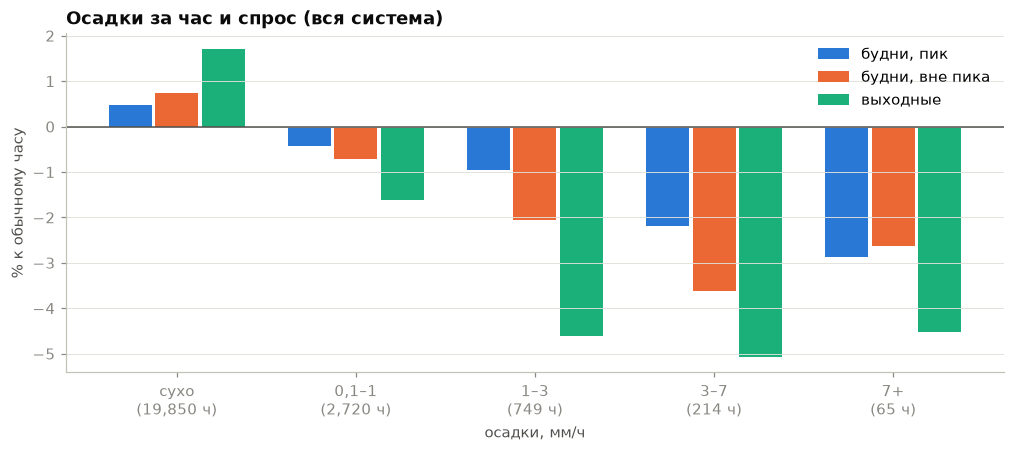

period,"будни, пик","будни, вне пика",выходные
b,,,
сухо,0.5,0.7,1.7
"0,1–1",-0.4,-0.7,-1.6
1–3,-1.0,-2.1,-4.6
3–7,-2.2,-3.6,-5.1
7+,-2.9,-2.6,-4.5


In [5]:
PERIODS = ["будни, пик", "будни, вне пика", "выходные"]

def effect_bars(t, col, bins, labels, title, xlabel):
    t = t.assign(b=pd.cut(t[col], bins=bins, labels=labels, right=False))
    tab = t.groupby(["b", "period"], observed=True)["ratio"].median().unstack()[PERIODS] - 1
    n = t.groupby("b", observed=True).size()
    fig, ax = plt.subplots()
    x = np.arange(len(tab)); wdt = 0.26
    for i, p in enumerate(PERIODS):
        ax.bar(x + (i - 1) * wdt, tab[p] * 100, width=wdt - 0.02, color=COL[i], label=p)
    ax.axhline(0, color=INK2, linewidth=1)
    ax.set_xticks(x, [f"{l}\n({n.get(l, 0):,} ч)" for l in tab.index])
    ax.set_xlabel(xlabel); ax.set_ylabel("% к обычному часу")
    ax.set_title(title); ax.legend(); ax.grid(axis="x", visible=False)
    plt.show()
    return (tab * 100).round(1)

display(effect_bars(by_sys, "precipitation", [0, 0.1, 1, 3, 7, 1000],
                    ["сухо", "0,1–1", "1–3", "3–7", "7+"],
                    "Осадки за час и спрос (вся система)", "осадки, мм/ч"))

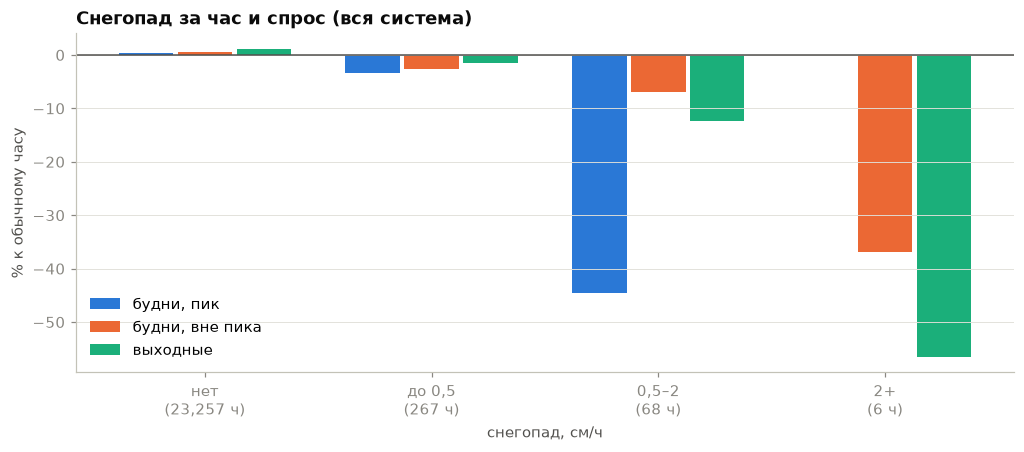

period,"будни, пик","будни, вне пика",выходные
b,,,
нет,0.4,0.6,1.1
"до 0,5",-3.3,-2.7,-1.5
"0,5–2",-44.5,-7.0,-12.3
2+,NaN,-36.8,-56.5


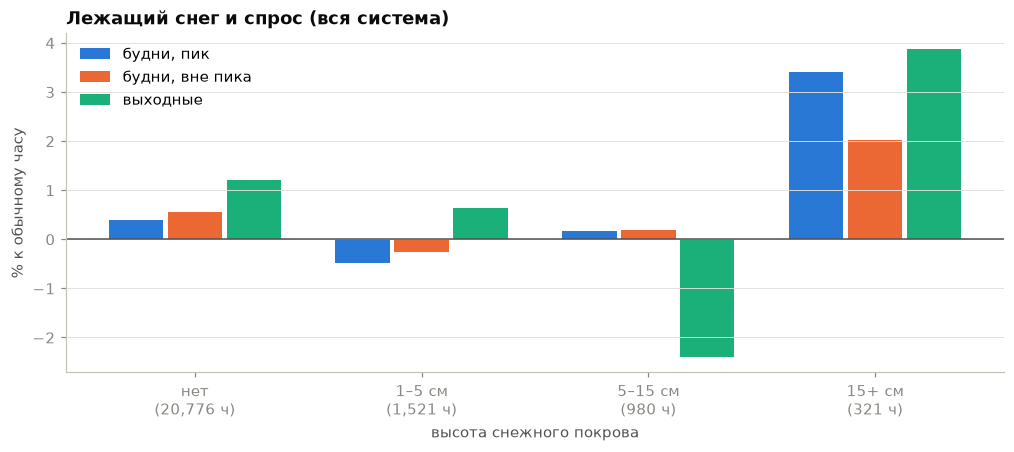

period,"будни, пик","будни, вне пика",выходные
b,,,
нет,0.4,0.6,1.2
1–5 см,-0.5,-0.3,0.6
5–15 см,0.2,0.2,-2.4
15+ см,3.4,2.0,3.9


In [6]:
display(effect_bars(by_sys, "snowfall", [0, 0.01, 0.5, 2, 1000],
                    ["нет", "до 0,5", "0,5–2", "2+"],
                    "Снегопад за час и спрос (вся система)", "снегопад, см/ч"))
display(effect_bars(by_sys, "snow_depth", [0, 0.01, 0.05, 0.15, 10],
                    ["нет", "1–5 см", "5–15 см", "15+ см"],
                    "Лежащий снег и спрос (вся система)", "высота снежного покрова"))

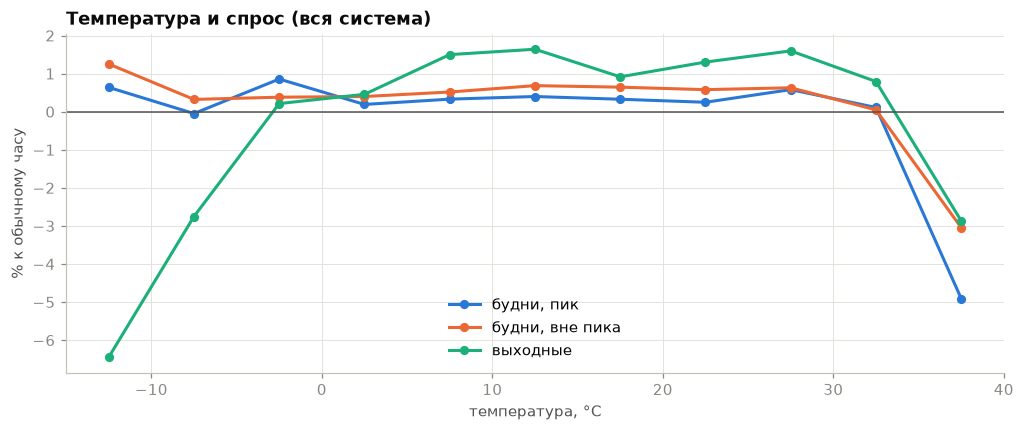

Важно: «обычный час» взят из того же месяца, поэтому здесь видна реакция на отклонение
температуры внутри месяца (необычно тёплый/холодный день), а не сезонность.


In [7]:
t = by_sys.assign(tb=pd.cut(by_sys["temperature_2m"], bins=range(-15, 41, 5)))
tab = t.groupby(["tb", "period"], observed=True)["ratio"].median().unstack()[PERIODS] - 1
fig, ax = plt.subplots()
mids = [iv.mid for iv in tab.index]
for i, p in enumerate(PERIODS):
    ax.plot(mids, tab[p] * 100, color=COL[i], marker="o", markersize=5, label=p)
ax.axhline(0, color=INK2, linewidth=1)
ax.set_xlabel("температура, °C"); ax.set_ylabel("% к обычному часу")
ax.set_title("Температура и спрос (вся система)")
ax.legend(); plt.show()
print("Важно: «обычный час» взят из того же месяца, поэтому здесь видна реакция на отклонение\n"
      "температуры внутри месяца (необычно тёплый/холодный день), а не сезонность.")

### Реакция на дождь по типам станций

Дождь — частое событие, поэтому на нём удобно сравнивать типы станций. Гипотеза: на деловых
станциях (поездки на работу) реакция слабее, чем на смешанных (досуг, поездки «по желанию»).

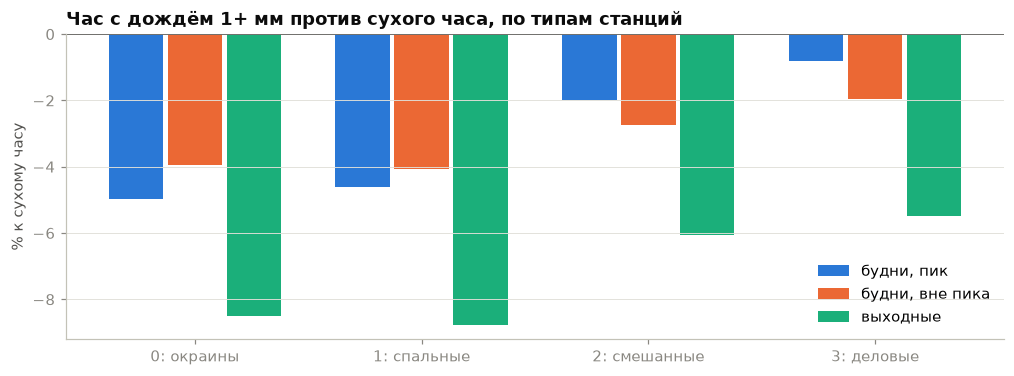

period,"будни, пик","будни, вне пика",выходные
0: окраины,-5.0,-4.0,-8.5
1: спальные,-4.6,-4.1,-8.8
2: смешанные,-2.0,-2.7,-6.0
3: деловые,-0.8,-2.0,-5.5


In [8]:
rain = by_cl.assign(r=pd.cut(by_cl["precipitation"], [0, 0.1, 1, 1000], labels=["сухо", "слабый", "1+ мм"], right=False))
tab = rain.groupby(["cluster", "period", "r"], observed=True)["ratio"].median().unstack("r")
eff = ((tab["1+ мм"] / tab["сухо"] - 1) * 100).unstack("period")[PERIODS]
eff.index = [f"{c}: {CL_NAMES.get(c, '')}" for c in eff.index]

fig, ax = plt.subplots(figsize=(11, 3.6))
x = np.arange(len(eff)); wdt = 0.26
for i, p in enumerate(PERIODS):
    ax.bar(x + (i - 1) * wdt, eff[p], width=wdt - 0.02, color=COL[i], label=p)
ax.axhline(0, color=INK2, linewidth=1)
ax.set_xticks(x, eff.index); ax.set_ylabel("% к сухому часу")
ax.set_title("Час с дождём 1+ мм против сухого часа, по типам станций")
ax.legend(); ax.grid(axis="x", visible=False); plt.show()
display(eff.round(1))

### Буран февраля 2026

Суточные входы относительно обычного дня (тот же день недели, тот же месяц) и снегопад за сутки.
Два графика с общей осью времени: у величин разные единицы, на одной оси их сравнивать нельзя.

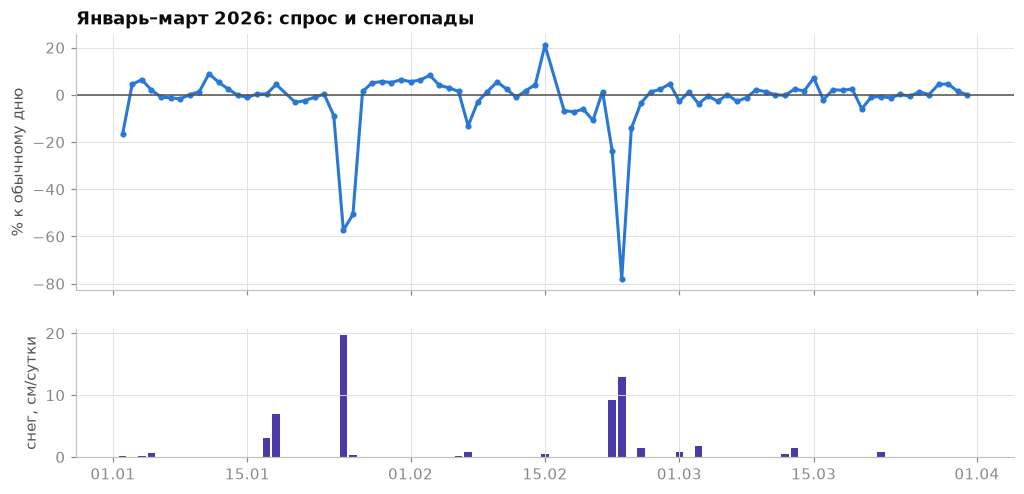

,день,к обычному,"снег за сутки, см","покров, м"
date,,,,
2026-02-23,Пн,-77.8%,12.88,0.48
2026-01-25,Вс,-57.4%,19.74,0.30
2026-01-26,Пн,-50.6%,0.28,0.28
2024-02-13,Вт,-37.2%,18.13,0.14
2024-12-26,Чт,-32.9%,0.00,0.03
2025-12-26,Пт,-32.5%,5.11,0.06
2023-12-26,Вт,-31.7%,0.00,0.00
2023-09-29,Пт,-30.9%,0.00,0.00
2025-12-27,Сб,-25.5%,3.01,0.09


10 худших дней за весь период (без праздников и закрытий): видно, какие из них погодные.


In [9]:
d = by_sys.assign(date=by_sys["transit_timestamp"].dt.normalize())
daily = d.groupby("date").agg(r=("ridership", "sum"), t=("typical", "sum"))
daily["ratio"] = daily["r"] / daily["t"] - 1
wd = w.assign(date=w["transit_timestamp"].dt.normalize()).groupby("date").agg(
    snow=("snowfall", "sum"), depth=("snow_depth", "max"))
win = daily.join(wd).loc["2026-01-01":"2026-03-31"]

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
a1.plot(win.index, win["ratio"] * 100, color=COL[0], marker="o", markersize=3)
a1.axhline(0, color=INK2, linewidth=1); a1.set_ylabel("% к обычному дню")
a1.set_title("Январь–март 2026: спрос и снегопады")
a2.bar(win.index, win["snow"], color=COL[6], width=0.8); a2.set_ylabel("снег, см/сутки")
a2.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
plt.show()

worst = daily.join(wd).nsmallest(10, "ratio")
display(worst.assign(**{"к обычному": worst["ratio"].map(pct), "день": worst.index.dayofweek.map(lambda i: DOW[i])})
             [["день", "к обычному", "snow", "depth"]].rename(columns={"snow": "снег за сутки, см", "depth": "покров, м"}))
print("10 худших дней за весь период (без праздников и закрытий): видно, какие из них погодные.")

## 3. Погода по городу или по районам

Два вопроса:
1. Как часто дождь **существенно** различается по городу (сильный в одном узле, сухо в другом)?
2. Объясняет ли **местный** дождь спрос около станции лучше, чем дождь в одной точке на весь город?

In [10]:
g = pd.read_parquet("../data/raw/weather_grid_0.1.parquet")[["grid_id", "transit_timestamp", "precipitation"]]
piv = g.pivot(index="transit_timestamp", columns="grid_id", values="precipitation")
mx, mn = piv.max(axis=1), piv.min(axis=1)
rows = []
for thr in [0.1, 1, 3, 7]:
    wet = mx >= thr
    rows.append({"порог «дождь», мм/ч": thr, "часов с таким дождём хоть где-то": int(wet.sum()),
                 "из них где-то сухо (< 0,1 мм)": f"{((mn < 0.1) & wet).sum() / max(wet.sum(), 1):.0%}"})
display(pd.DataFrame(rows))

,"порог «дождь», мм/ч",часов с таким дождём хоть где-то,"из них где-то сухо (< 0,1 мм)"
0,0.1,7322,57%
1,1.0,2628,27%
2,3.0,1022,21%
3,7.0,274,17%


In [11]:
gmap = st.set_index("station_complex_id")["grid_01"]
base["grid_id"] = base["station_complex_id"].astype(str).map(gmap)
by_node = (base.groupby(["grid_id", "transit_timestamp"], observed=True)[["ridership", "typical"]].sum()
               .reset_index())
by_node = by_node.merge(g.rename(columns={"precipitation": "p_local"}), on=["grid_id", "transit_timestamp"])
by_node = by_node.merge(w[["transit_timestamp", "precipitation"]].rename(columns={"precipitation": "p_city"}),
                        on="transit_timestamp")
by_node["hour"] = by_node["transit_timestamp"].dt.hour
by_node = by_node[(by_node["typical"] > 0) & by_node["hour"].between(6, 23)]
by_node["y"] = np.log(by_node["ridership"].clip(lower=1) / by_node["typical"])

wet = by_node[(by_node["p_local"] > 0.1) | (by_node["p_city"] > 0.1)]
diverge = wet[(wet["p_local"] - wet["p_city"]).abs() > 1]

def r2(t, col):
    if len(t) < 30:
        return np.nan
    return np.corrcoef(np.log1p(t[col]), t["y"])[0, 1] ** 2

res = pd.DataFrame(
    {"все часы с дождём": [r2(wet, "p_local"), r2(wet, "p_city")],
     "часы, где местный и городской дождь расходятся > 1 мм": [r2(diverge, "p_local"), r2(diverge, "p_city")]},
    index=["местный дождь (узел сетки)", "городской дождь (1 точка)"])
display(res.round(4))
print(f"Наблюдений (узел × час): {len(wet):,}; из них с расхождением > 1 мм: "
      f"{((wet['p_local'] - wet['p_city']).abs() > 1).sum():,}")
print("R² здесь маленький по определению: дождь объясняет малую часть колебаний спроса.\n"
      "Важно не само значение, а сравнение строк: какой источник дождя объясняет больше.")

,все часы с дождём,"часы, где местный и городской дождь расходятся > 1 мм"
местный дождь (узел сетки),0.0203,0.0131
городской дождь (1 точка),0.0177,0.0085


Наблюдений (узел × час): 34,354; из них с расхождением > 1 мм: 5,133
R² здесь маленький по определению: дождь объясняет малую часть колебаний спроса.
Важно не само значение, а сравнение строк: какой источник дождя объясняет больше.


## 4. Плата за въезд: «разность разностей»

Сравниваем рост спроса год к году на станциях **в зоне платы** и **остальных**:
- 2024 против 2023 — **проверка (плацебо)**: платы ещё не было, рост групп должен быть похожим;
- 2025 против 2024 — после введения платы.

Если в 2025 зона росла быстрее остальных, а в 2024 — нет, это аргумент в пользу эффекта платы.
Берём будни без праздников и закрытий; в каждом месяце сравниваем только станции, открытые в оба года.

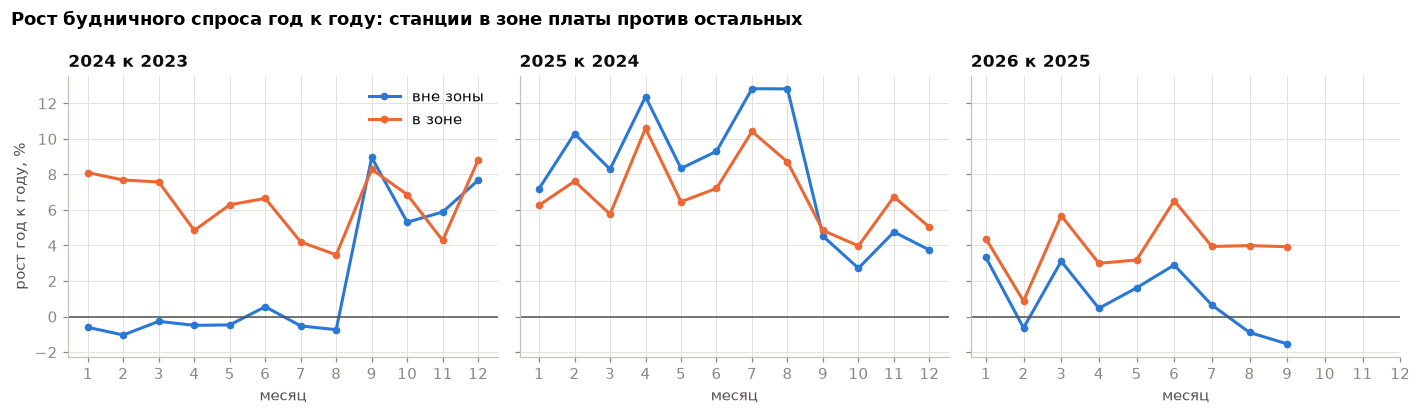

,сравнение,рост в зоне,рост вне зоны,разница (зона − остальные),месяцев
0,2024 к 2023,+6.4%,+2.0%,+4.4%,12
1,2025 к 2024,+7.0%,+8.0%,-1.0%,12
2,2026 к 2025,+3.9%,+1.0%,+2.9%,9


In [12]:
wkd = df[(df["is_closed"] == 0) & (df["dow"] < 5) & (df["is_holiday"] == 0)]
sd = wkd.groupby(["station_complex_id", "date"], observed=True)["ridership"].sum().reset_index()
sd["year"], sd["month"] = sd["date"].dt.year, sd["date"].dt.month
sm = sd.groupby(["station_complex_id", "year", "month"], observed=True)["ridership"].mean().unstack("year")
sm = sm.join(st.set_index("station_complex_id")["in_cbd"], on="station_complex_id")

def yoy(y1, y0):
    t = sm.dropna(subset=[y0, y1])
    s = t.groupby(["month", "in_cbd"])[[y0, y1]].sum()
    return (s[y1] / s[y0] - 1).unstack("in_cbd").rename(columns={0: "вне зоны", 1: "в зоне"})

pairs = [(2024, 2023), (2025, 2024), (2026, 2025)]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
summary = []
for ax, (y1, y0) in zip(axes, pairs):
    g_ = yoy(y1, y0)
    for i, c in enumerate(["вне зоны", "в зоне"]):
        ax.plot(g_.index, g_[c] * 100, color=COL[i], marker="o", markersize=4, label=c)
    ax.axhline(0, color=INK2, linewidth=1); ax.set_title(f"{y1} к {y0}", fontsize=11)
    ax.set_xticks(range(1, 13)); ax.set_xlabel("месяц")
    diff = (np.log1p(g_["в зоне"]) - np.log1p(g_["вне зоны"])).mean()
    summary.append({"сравнение": f"{y1} к {y0}", "рост в зоне": pct(np.expm1(np.log1p(g_['в зоне']).mean())),
                    "рост вне зоны": pct(np.expm1(np.log1p(g_['вне зоны']).mean())),
                    "разница (зона − остальные)": pct(np.expm1(diff)), "месяцев": len(g_)})
axes[0].set_ylabel("рост год к году, %"); axes[0].legend()
fig.suptitle("Рост будничного спроса год к году: станции в зоне платы против остальных",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); plt.show()
summary = pd.DataFrame(summary)
display(summary)

Разность разностей (2025 vs 2024 минус плацебо 2024 vs 2023): -5.2%


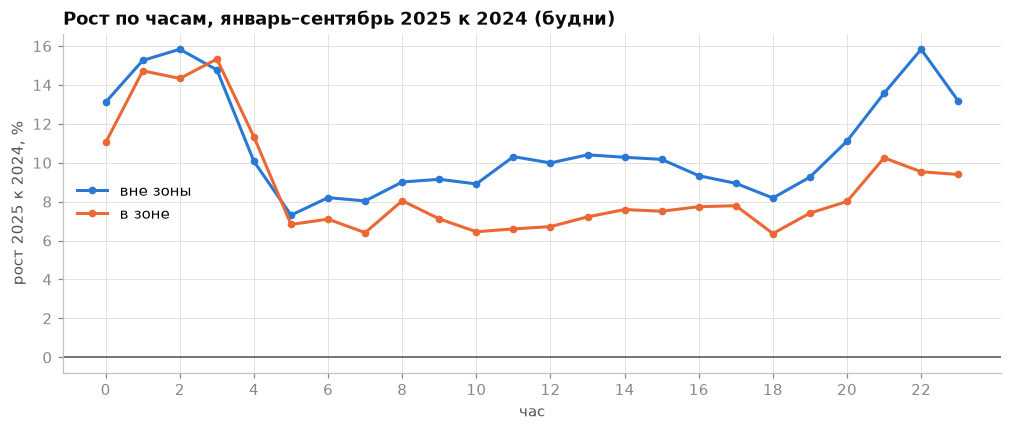

Входы на станциях В ЗОНЕ вечером — это люди, уезжающие из центра: те, кто раньше ездил на машине,
должны давать рост именно в утренние входы вне зоны и вечерние входы в зоне.


In [13]:
# Оценка «разность разностей» и где по времени суток сосредоточен эффект
s24, s25 = summary.iloc[0], summary.iloc[1]
did = (1 + float(s25["разница (зона − остальные)"].strip("%")) / 100) / \
      (1 + float(s24["разница (зона − остальные)"].strip("%")) / 100) - 1
print(f"Разность разностей (2025 vs 2024 минус плацебо 2024 vs 2023): {did:+.1%}")

hh = wkd[wkd["date"].dt.month <= 9]
hm = (hh.groupby(["station_complex_id", hh["date"].dt.year.rename("year"), "hour"], observed=True)["ridership"]
        .mean().unstack("year"))
hm = hm.join(st.set_index("station_complex_id")["in_cbd"], on="station_complex_id").dropna(subset=[2024, 2025])
hs = hm.groupby(["hour", "in_cbd"])[[2024, 2025]].sum()
hy = (hs[2025] / hs[2024] - 1).unstack("in_cbd").rename(columns={0: "вне зоны", 1: "в зоне"})

fig, ax = plt.subplots()
for i, c in enumerate(["вне зоны", "в зоне"]):
    ax.plot(hy.index, hy[c] * 100, color=COL[i], marker="o", markersize=4, label=c)
ax.axhline(0, color=INK2, linewidth=1)
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("час"); ax.set_ylabel("рост 2025 к 2024, %")
ax.set_title("Рост по часам, январь–сентябрь 2025 к 2024 (будни)"); ax.legend(); plt.show()
print("Входы на станциях В ЗОНЕ вечером — это люди, уезжающие из центра: те, кто раньше ездил на машине,\n"
      "должны давать рост именно в утренние входы вне зоны и вечерние входы в зоне.")

## 5. События: поиск всплесков на всех станциях

Для каждой станции и дня считаем входы в двух окнах — **день 11–16 ч** и **вечер 17–23 ч** — и
сравниваем с «обычным» значением: 30-й перцентиль того же дня недели за ±8 недель (устойчив, даже если
события идут через день). **Всплеск** = в 1,5 раза выше обычного **и** минимум на 300 входов больше.

Затем разделяем два типа:
- **местные события** — станция регулярно «всплескивает» одна (стадион, концертная площадка);
- **городские события** — в один день всплески сразу на многих станциях (марафон, парады, салют).

In [14]:
op = df[df["is_closed"] == 0]
windows = {"день 11–16": op["hour"].between(11, 16), "вечер 17–23": op["hour"].between(17, 23)}
spk = []
for label, m in windows.items():
    s = op[m].groupby(["station_complex_id", "date"], observed=True)["ridership"].sum().reset_index()
    s["dow"] = s["date"].dt.dayofweek
    s = s.sort_values(["station_complex_id", "dow", "date"])
    s["base"] = (s.groupby(["station_complex_id", "dow"], observed=True)["ridership"]
                  .transform(lambda x: x.rolling(17, center=True, min_periods=6).quantile(0.3)))
    s["ratio"] = s["ridership"] / s["base"]
    s["excess"] = s["ridership"] - s["base"]
    s["window"] = label
    spk.append(s)
spk = pd.concat(spk, ignore_index=True)
spk["station_complex_id"] = spk["station_complex_id"].astype(str)
spk["is_spike"] = (spk["ratio"] >= 1.5) & (spk["excess"] >= 300)
spikes = spk[spk["is_spike"]].copy()
print(f"Станционных окон: {len(spk):,}; всплесков: {len(spikes):,} ({len(spikes) / len(spk):.2%})")

Станционных окон: 1,136,698; всплесков: 17,347 (1.53%)


In [15]:
# Городские события: дни, когда всплеск сразу на многих станциях
per_day = spikes.groupby(["date", "window"]).agg(станций=("station_complex_id", "nunique"),
                                                 лишних_входов=("excess", "sum")).reset_index()
CITY_MIN = 15   # порог «городского» дня: всплеск на 15+ станциях в одном окне
city_days = per_day[per_day["станций"] >= CITY_MIN].sort_values("лишних_входов", ascending=False)
hol = df.drop_duplicates("date").set_index("date")["holiday_name"].astype(str)
city_days = city_days.assign(день=city_days["date"].dt.dayofweek.map(lambda i: DOW[i]),
                             праздник=city_days["date"].map(hol).fillna(""))
print(f"Дней-окон с всплеском на {CITY_MIN}+ станциях: {len(city_days)}")
display(city_days.head(25).assign(date=lambda t: t["date"].dt.strftime("%d.%m.%Y"),
                                  лишних_входов=lambda t: t["лишних_входов"].round(-2).astype(int)))

Дней-окон с всплеском на 15+ станциях: 381


,date,window,станций,лишних_входов,день,праздник
1772,02.11.2025,день 11–16,77,303600,Вс,
1138,03.11.2024,день 11–16,74,277800,Вс,
516,05.11.2023,день 11–16,89,231500,Вс,
1212,14.12.2024,вечер 17–23,53,164700,Сб,
569,09.12.2023,вечер 17–23,60,148700,Сб,
1840,13.12.2025,вечер 17–23,48,143800,Сб,
1213,14.12.2024,день 11–16,45,140500,Сб,
556,02.12.2023,вечер 17–23,53,131400,Сб,
1198,07.12.2024,вечер 17–23,46,121800,Сб,
610,31.12.2023,вечер 17–23,112,118800,Вс,New Year's Eve


In [16]:
# Местные события: станции, которые регулярно «всплескивают» не в городские дни
city_keys = set(zip(city_days["date"], city_days["window"]))
local = spikes[[k not in city_keys for k in zip(spikes["date"], spikes["window"])]]
years = (df["date"].max() - df["date"].min()).days / 365.25

stn = (local.groupby("station_complex_id")
            .agg(всплесков=("date", "size"), макс_рост=("ratio", "max"),
                 медиана_лишних=("excess", "median"),
                 доля_вечер=("window", lambda x: (x == "вечер 17–23").mean()))
            .reset_index())
stn["в_год"] = stn["всплесков"] / years
stn["станция"] = stn["station_complex_id"].map(name)
stn = stn.sort_values("всплесков", ascending=False)

LOCAL_MIN = 10   # «регулярные события»: 10+ всплесков в год
event_st = stn[stn["в_год"] >= LOCAL_MIN]
print(f"Станций с хотя бы одним местным всплеском: {len(stn)}; с {LOCAL_MIN}+ всплесками в год: {len(event_st)}")
display(stn.head(30)[["станция", "всплесков", "в_год", "макс_рост", "медиана_лишних", "доля_вечер"]]
           .round({"в_год": 1, "макс_рост": 1, "медиана_лишних": -1, "доля_вечер": 2}))

Станций с хотя бы одним местным всплеском: 329; с 10+ всплесками в год: 67


,станция,всплесков,в_год,макс_рост,медиана_лишних,доля_вечер
248,Mets-Willets Point (7),553,148.3,34.8,5370.0,0.69
274,"161 St-Yankee Stadium (4,B,D)",369,99.0,9.4,12110.0,0.76
143,116 St-Columbia University (1),310,83.1,3.2,2350.0,0.79
268,"W 8 St-NY Aquarium (F,Q)",231,61.9,5.2,470.0,0.75
131,Fulton St (G),225,60.3,3.2,940.0,0.31
200,Bedford Park Blvd-Lehman College (4),208,55.8,2.3,490.0,0.47
216,68 St-Hunter College (6),194,52.0,2.3,3880.0,0.65
269,"Coney Island-Stillwell Av (D,F,N,Q)",192,51.5,3.7,1850.0,0.91
284,"Atlantic Av-Barclays Ctr (2,3,4,5,B,D,N,Q,R)",153,41.0,2.1,6060.0,0.95
257,33 St-Rawson St (7),113,30.3,3.3,1610.0,0.36


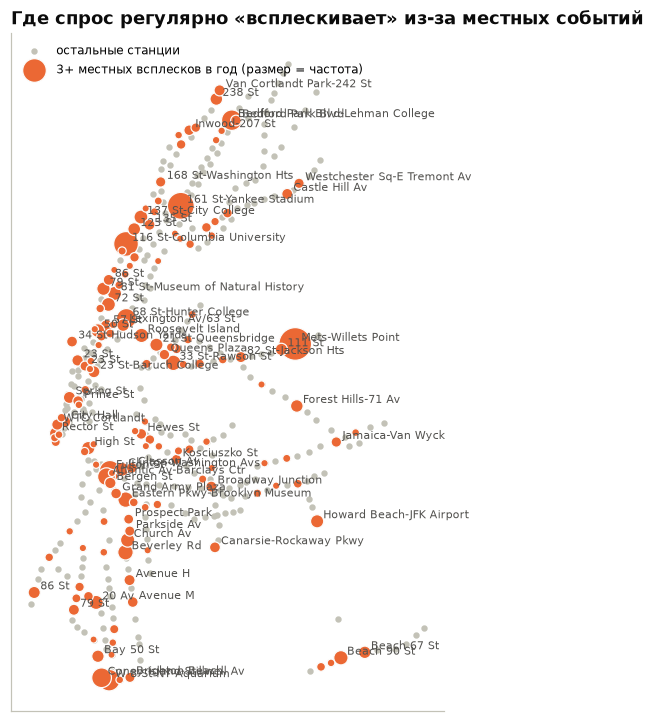

In [17]:
geo = st.set_index("station_complex_id")
fig, ax = plt.subplots(figsize=(7, 8))
ax.scatter(geo["longitude"], geo["latitude"], s=10, color="#c3c2b7", label="остальные станции")
e = stn.set_index("station_complex_id").join(geo[["longitude", "latitude"]])
e = e[e["в_год"] >= 3]
sc = ax.scatter(e["longitude"], e["latitude"], s=12 + e["в_год"] * 3, color=COL[1],
                edgecolor="#fcfcfb", linewidth=0.8, label="3+ местных всплесков в год (размер = частота)")
for sid, r in e[e["в_год"] >= LOCAL_MIN].iterrows():
    ax.annotate(str(r["станция"]).split(" (")[0], (r["longitude"], r["latitude"]), fontsize=7.5,
                color=INK2, xytext=(4, 2), textcoords="offset points")
ax.set_aspect(1 / np.cos(np.radians(40.7))); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax.set_title("Где спрос регулярно «всплескивает» из-за местных событий"); ax.legend(loc="upper left", fontsize=8)
plt.show()

In [18]:
# Насколько события весят в общей картине
tot = df.loc[df["is_closed"] == 0, "ridership"].sum()
share_local = local["excess"].sum() / tot
share_city = spikes[[k in city_keys for k in zip(spikes["date"], spikes["window"])]]["excess"].sum() / tot
print(f"Лишние входы при местных всплесках: {share_local:.2%} всех входов")
print(f"Лишние входы при городских всплесках: {share_city:.2%} всех входов")
for sid in event_st["station_complex_id"]:
    s_ = spk[spk["station_complex_id"] == sid]
    st_tot = s_["ridership"].sum()
    st_ex = s_.loc[s_["is_spike"], "excess"].sum()
    print(f"  {name.get(sid, sid)[:55]:55s}: всплески дают {st_ex / st_tot:.0%} входов этой станции в окнах 11–23 ч")

spikes.assign(station_complex=spikes["station_complex_id"].map(name)).to_csv(
    "../data/processed/event_spikes.csv", index=False)
stn.to_csv("../data/processed/event_stations.csv", index=False)
print("Сохранено: data/processed/event_spikes.csv, event_stations.csv")

Лишние входы при местных всплесках: 0.40% всех входов
Лишние входы при городских всплесках: 0.33% всех входов
  Mets-Willets Point (7)                                 : всплески дают 64% входов этой станции в окнах 11–23 ч
  161 St-Yankee Stadium (4,B,D)                          : всплески дают 33% входов этой станции в окнах 11–23 ч
  116 St-Columbia University (1)                         : всплески дают 8% входов этой станции в окнах 11–23 ч
  W 8 St-NY Aquarium (F,Q)                               : всплески дают 12% входов этой станции в окнах 11–23 ч
  Fulton St (G)                                          : всплески дают 8% входов этой станции в окнах 11–23 ч
  Bedford Park Blvd-Lehman College (4)                   : всплески дают 7% входов этой станции в окнах 11–23 ч
  68 St-Hunter College (6)                               : всплески дают 5% входов этой станции в окнах 11–23 ч
  Coney Island-Stillwell Av (D,F,N,Q)                    : всплески дают 9% входов этой станции в окнах

## Что зафиксировать

1. **Тип станции:** насколько кластеры совпадают с отрезками `commute_index`? Какие станции на краях шкалы?
2. **Дождь:** на сколько процентов падает спрос при 1–3 и 3–7 мм/ч? В какие часы сильнее — пик или вне пика,
   будни или выходные? Какой тип станций реагирует сильнее?
3. **Снег и буран:** насколько упал спрос в худшие дни и все ли худшие дни объясняются погодой?
4. **Город или сетка:** как часто дождь существенно различается по городу; объясняет ли местный дождь больше,
   чем городской? Это аргумент «за» или «против» эксперимента с уровнями погоды.
5. **Плата за въезд:** была ли разница между зоной и остальными в 2024 (плацебо) и стала ли больше в 2025?
   В какие часы?
6. **События:** сколько станций с регулярными местными событиями? Какие городские дни нашлись?
   Это определяет решение: широкий признак, узкий или отказ.